# Week 4 - Invoice Late Payment Classification

## Project objective
Build a classification system that estimates the probability of late payment for an invoice.

**Prediction point:** Invoice posting date.

**Target:** `late_payment` (1 = late, 0 = on-time or early).

This notebook documents data preparation, chronological evaluation, model comparison, cross-validation, probability calibration and invoice risk predictions.

The model is evaluated on historical settled invoices. Open invoices have unknown outcomes and are used only for inference.


## 1. Methodology and data controls

The modelling workflow follows chronological partitions:

| Partition | Period | Purpose |
|---|---|---|
| Training | Through August 31, 2019 | Model fitting |
| Validation | September-November 2019 | Model and threshold comparison |
| Calibration | December 2019-January 2020 | Sigmoid calibration |
| Final test | February 1-27, 2020 | Independent evaluation |

The model uses 17 approved features. `total_open_amount` is excluded because its business meaning has not been confirmed.

Outcome fields, customer identifiers and invoice identifiers are not model inputs.

Customer historical features must represent only information available before the current invoice's posting date.


In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "notebooks"
    else CURRENT_DIR
)

DATA_DIR = PROJECT_ROOT / "datasets" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "week4_modeling"
MODEL_DIR = PROJECT_ROOT / "models"

print("Project directory:", Path.cwd())
print("Report directory exists:", REPORT_DIR.exists())


Project directory: C:\invioce_data\notebooks
Report directory exists: True


## 2. Load data and define approved features

In [2]:
data_path = DATA_DIR / "invoices_features_all.parquet"

df = pd.read_parquet(data_path)
df["posting_date"] = pd.to_datetime(df["posting_date"])

features = [
    "business_code",
    "invoice_currency",
    "document_type",
    "cust_payment_terms",
    "has_customer_payment_history",
    "invoice_year",
    "invoice_month",
    "invoice_day",
    "invoice_day_of_week",
    "payment_term_days",
    "posting_to_due_days",
    "is_due_date_anomaly",
    "customer_previous_invoice_count",
    "customer_previous_cleared_count",
    "customer_previous_late_rate",
    "customer_previous_avg_delay",
    "customer_previous_median_delay"
]

forbidden_features = [
    "late_payment",
    "clear_date",
    "payment_delay_days",
    "days_to_clear",
    "posting_date",
    "total_open_amount",
    "invoice_id",
    "doc_id",
    "cust_number",
    "is_open"
]

missing_features = [col for col in features if col not in df.columns]
assert not missing_features, f"Missing features: {missing_features}"
assert not set(features).intersection(forbidden_features)

print("Full dataset shape:", df.shape)
print("Approved feature count:", len(features))
print("Missing approved features:", missing_features)
print("Settled invoices:", int(df["late_payment"].notna().sum()))
print("Open invoices:", int(df["late_payment"].isna().sum()))

display(df[features].dtypes.rename("data_type").to_frame())


Full dataset shape: (48839, 34)
Approved feature count: 17
Missing approved features: []
Settled invoices: 39158
Open invoices: 9681


,data_type
business_code,string[python]
invoice_currency,string[python]
document_type,string[python]
cust_payment_terms,string[python]
has_customer_payment_history,int8
invoice_year,int32
invoice_month,int32
invoice_day,int32
invoice_day_of_week,int32
payment_term_days,int64


## 3. Chronological data partitions

In [3]:
labelled = df[df["late_payment"].notna()].copy()
labelled["late_payment"] = labelled["late_payment"].astype(int)

train = labelled[labelled["posting_date"] <= "2019-08-31"].copy()

validation = labelled[
    (labelled["posting_date"] >= "2019-09-01") &
    (labelled["posting_date"] <= "2019-11-30")
].copy()

calibration = labelled[
    (labelled["posting_date"] >= "2019-12-01") &
    (labelled["posting_date"] <= "2020-01-31")
].copy()

test = labelled[
    (labelled["posting_date"] >= "2020-02-01") &
    (labelled["posting_date"] <= "2020-02-27")
].copy()

partition_summary = pd.DataFrame([
    ["Training", len(train), train["posting_date"].min(), train["posting_date"].max()],
    ["Validation", len(validation), validation["posting_date"].min(), validation["posting_date"].max()],
    ["Calibration", len(calibration), calibration["posting_date"].min(), calibration["posting_date"].max()],
    ["Final test", len(test), test["posting_date"].min(), test["posting_date"].max()]
], columns=["partition", "rows", "start_date", "end_date"])

display(partition_summary)

print("Training target counts:")
display(train["late_payment"].value_counts().sort_index().to_frame("invoices"))

assert len(train) == 23716
assert len(validation) == 8679
assert len(calibration) == 4404
assert len(test) == 2359


,partition,rows,start_date,end_date
0,Training,23716,2018-12-30,2019-08-31
1,Validation,8679,2019-09-01,2019-11-30
2,Calibration,4404,2019-12-01,2020-01-31
3,Final test,2359,2020-02-01,2020-02-27


Training target counts:


,invoices
late_payment,
0,13575
1,10141


## 4. Initial model comparison

The following table contains the recorded September-November validation results from the model experiments.

The imbalance handling differs between experiments: Random Forest used balanced class weights, weighted XGBoost used `scale_pos_weight`, and Logistic Regression and unweighted XGBoost did not use class weighting. Keep this limitation in mind when comparing them.


In [4]:
comparison = pd.read_csv(REPORT_DIR / "model_comparison.csv")
display(comparison.sort_values("f1", ascending=False))


,model,imbalance_method,accuracy,precision,recall,f1,roc_auc,pr_auc
2,Random Forest,class_weight=balanced,0.7942,0.7577,0.7473,0.7525,0.8504,0.8252
4,XGBoost,scale_pos_weight=1.3386,0.7968,0.7716,0.7308,0.7506,0.8549,0.8349
3,XGBoost,Unweighted,0.7981,0.7905,0.7044,0.7450,0.8544,0.8350
1,Logistic Regression,NaN,0.7458,0.7305,0.6224,0.6721,0.8101,0.7631
0,Majority baseline,NaN,0.5814,0.0000,0.0000,0.0000,NaN,NaN


## 5. Five-fold expanding-window time-aware cross-validation

The folds split unique posting dates, rather than invoice rows. Invoices posted on the same date remain in one partition.

Preprocessing is fitted separately within each fold. The classification threshold for this comparison is 0.50.


In [5]:
cv_summary = pd.read_csv(REPORT_DIR / "time_cv_summary.csv")
cv_folds = pd.read_csv(REPORT_DIR / "time_cv_fold_results.csv")

display(cv_summary)
display(cv_folds.head(10))

print("Fold count:", cv_folds["fold"].nunique())
print("Unique models:", cv_folds["model"].nunique())


,model,folds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
0,Random Forest,5,0.778869,0.020487,0.742981,0.035537,0.734570,0.028940,0.738231,0.023545,0.833175,0.024404,0.806162,0.038538
1,XGBoost weighted,5,0.778025,0.023425,0.754981,0.045291,0.709968,0.037347,0.730784,0.027319,0.833780,0.026577,0.808749,0.043253
2,XGBoost unweighted,5,0.782383,0.025104,0.779962,0.046409,0.682024,0.038568,0.726779,0.029950,0.834730,0.024271,0.809798,0.042206
3,Logistic Regression,5,0.740269,0.017365,0.744942,0.035784,0.593667,0.049872,0.659196,0.029334,0.802100,0.018460,0.759145,0.027726
4,Majority baseline,5,0.575361,0.011647,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN


,fold,model,training_rows,validation_rows,training_start,training_end,validation_start,validation_end,threshold,validation_late_rate,accuracy,precision,recall,f1,roc_auc,pr_auc,scale_pos_weight
0,1,Majority baseline,3852,4019,2018-12-30,2019-02-12,2019-02-13,2019-03-24,0.5,0.428216,0.571784,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,1,Logistic Regression,3852,4019,2018-12-30,2019-02-12,2019-02-13,2019-03-24,0.5,0.428216,0.723314,0.702595,0.613597,0.655087,0.779250,0.729275,NaN
2,1,Random Forest,3852,4019,2018-12-30,2019-02-12,2019-02-13,2019-03-24,0.5,0.428216,0.756905,0.706897,0.738524,0.722364,0.810411,0.760929,NaN
3,1,XGBoost unweighted,3852,4019,2018-12-30,2019-02-12,2019-02-13,2019-03-24,0.5,0.428216,0.745708,0.716409,0.672284,0.693645,0.805676,0.752561,NaN
4,1,XGBoost weighted,3852,4019,2018-12-30,2019-02-12,2019-02-13,2019-03-24,0.5,0.428216,0.744215,0.699712,0.705404,0.702546,0.799207,0.748747,1.255269
5,2,Majority baseline,7871,4214,2018-12-30,2019-03-24,2019-03-25,2019-05-03,0.5,0.415520,0.584480,0.000000,0.000000,0.000000,NaN,NaN,NaN
6,2,Logistic Regression,7871,4214,2018-12-30,2019-03-24,2019-03-25,2019-05-03,0.5,0.415520,0.736355,0.721300,0.595660,0.652487,0.789137,0.740724,NaN
7,2,Random Forest,7871,4214,2018-12-30,2019-03-24,2019-03-25,2019-05-03,0.5,0.415520,0.760085,0.708333,0.718447,0.713354,0.806465,0.771277,NaN
8,2,XGBoost unweighted,7871,4214,2018-12-30,2019-03-24,2019-03-25,2019-05-03,0.5,0.415520,0.770764,0.752087,0.668761,0.707981,0.812916,0.780137,NaN
9,2,XGBoost weighted,7871,4214,2018-12-30,2019-03-24,2019-03-25,2019-05-03,0.5,0.415520,0.765306,0.726786,0.697316,0.711746,0.813568,0.779969,1.295421


Fold count: 5
Unique models: 5


## 6. Random Forest threshold analysis

In [6]:
thresholds = pd.read_csv(REPORT_DIR / "threshold_analysis.csv")
display(thresholds)

best_threshold_row = thresholds.loc[thresholds["f1"].idxmax()]
print("Best tested threshold:", best_threshold_row["threshold"])
print("Validation F1:", best_threshold_row["f1"])
print("Validation precision:", best_threshold_row["precision"])
print("Validation recall:", best_threshold_row["recall"])


,threshold,precision,recall,f1
0,0.30,0.6564,0.8376,0.7360
1,0.35,0.6937,0.8142,0.7491
2,0.40,0.7202,0.7936,0.7551
3,0.45,0.7334,0.7740,0.7532
4,0.50,0.7577,0.7473,0.7525
5,0.55,0.7759,0.7165,0.7450
6,0.60,0.8010,0.6746,0.7324
7,0.65,0.8373,0.6149,0.7091
8,0.70,0.8640,0.5279,0.6554


Best tested threshold: 0.4
Validation F1: 0.7551
Validation precision: 0.7202
Validation recall: 0.7936


## 7. Probability calibration

The Random Forest was fitted on the training partition. A sigmoid calibrator was fitted using the separate December 2019-January 2020 calibration partition.

The February 2020 final test partition was not used to fit the model or calibrator.


,model,brier_score,log_loss,test_rows
0,Uncalibrated Random Forest,0.158764,0.487512,2359
1,Sigmoid Calibrated Random Forest,0.155073,0.477883,2359


Brier score improvement: 0.003692
Log loss improvement: 0.009629


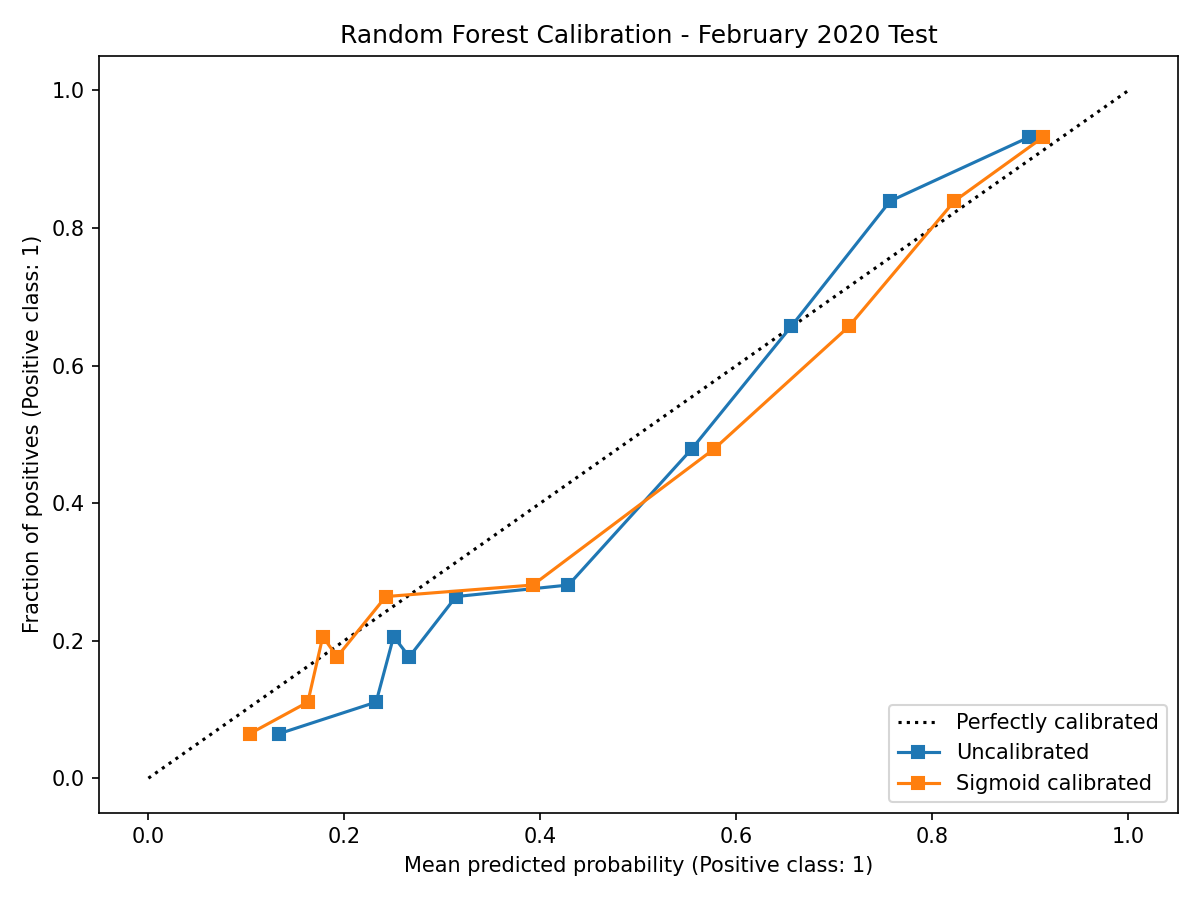

In [7]:
calibration_metrics = pd.read_csv(
    REPORT_DIR / "calibration_test_metrics.csv"
)
display(calibration_metrics)

brier_change = (
    calibration_metrics.iloc[0]["brier_score"] -
    calibration_metrics.iloc[1]["brier_score"]
)
logloss_change = (
    calibration_metrics.iloc[0]["log_loss"] -
    calibration_metrics.iloc[1]["log_loss"]
)

print("Brier score improvement:", round(brier_change, 6))
print("Log loss improvement:", round(logloss_change, 6))

display(Image(filename=str(REPORT_DIR / "calibration_curve_test.png")))


## 8. Final February 2020 test evaluation

In [8]:
final_metrics = pd.read_csv(
    REPORT_DIR / "final_test_classification_metrics.csv"
)
display(final_metrics)

confusion = pd.read_csv(
    REPORT_DIR / "final_test_confusion_matrix.csv",
    index_col=0
)
display(confusion)

error_analysis = pd.read_csv(
    REPORT_DIR / "final_test_error_analysis.csv"
)
display(error_analysis)

classification_report = pd.read_csv(
    REPORT_DIR / "final_test_classification_report.csv",
    index_col=0
)
display(classification_report)


,model,accuracy,precision,recall,f1,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives
0,Uncalibrated Random Forest,0.760916,0.675253,0.77672,0.722441,0.838856,0.805223,1061,353,211,734
1,Sigmoid Calibrated Random Forest,0.760916,0.675253,0.77672,0.722441,0.838856,0.805223,1061,353,211,734


,Predicted on-time,Predicted late
Actual on-time,1061,353
Actual late,211,734


,error_type,count,meaning
0,False positives,353,On-time invoices incorrectly flagged as late
1,False negatives,211,Late invoices missed by the model
2,True positives,734,Late invoices correctly identified
3,True negatives,1061,On-time invoices correctly identified


,precision,recall,f1-score,support
On-time,0.834119,0.750354,0.790022,1414.000000
Late,0.675253,0.776720,0.722441,945.000000
accuracy,0.760916,0.760916,0.760916,0.760916
macro avg,0.754686,0.763537,0.756232,2359.000000
weighted avg,0.770479,0.760916,0.762950,2359.000000


## 9. Final test performance plots

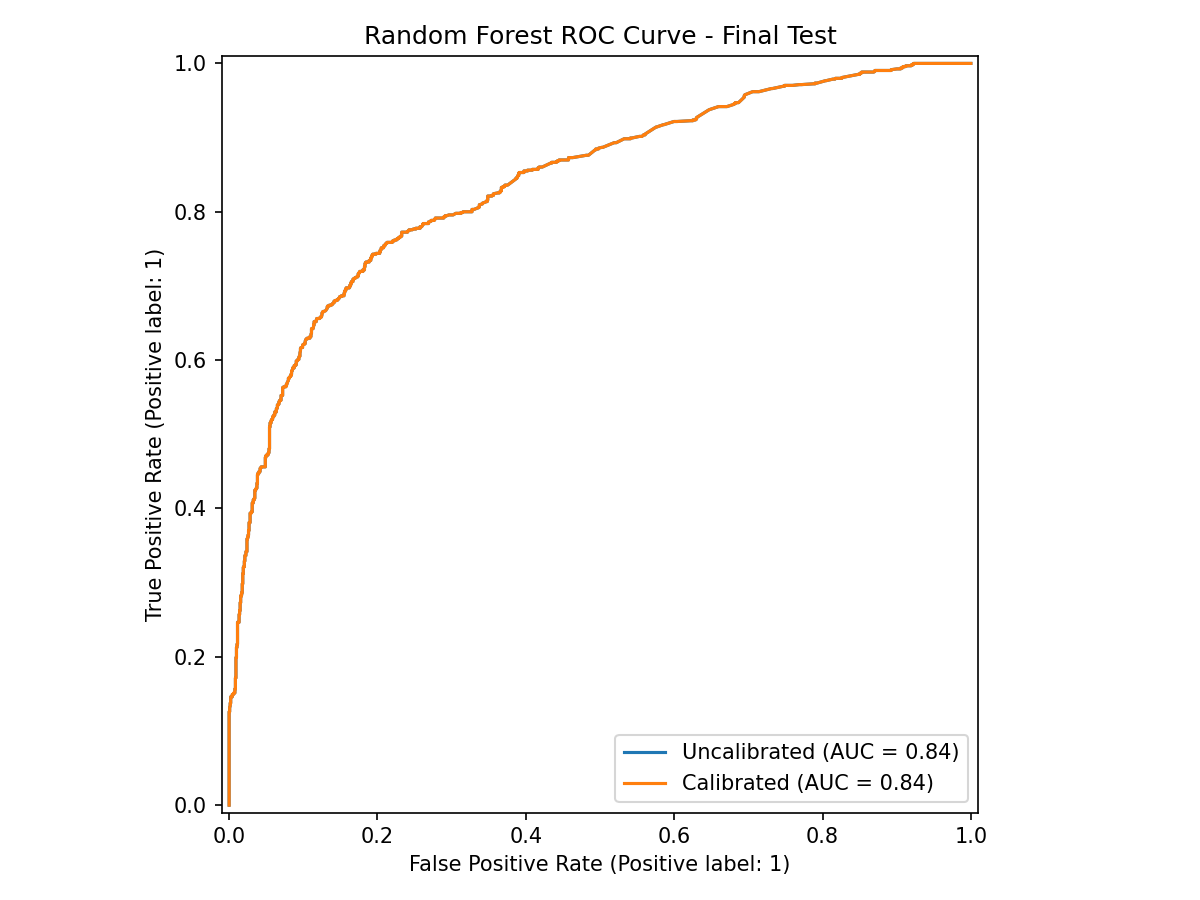

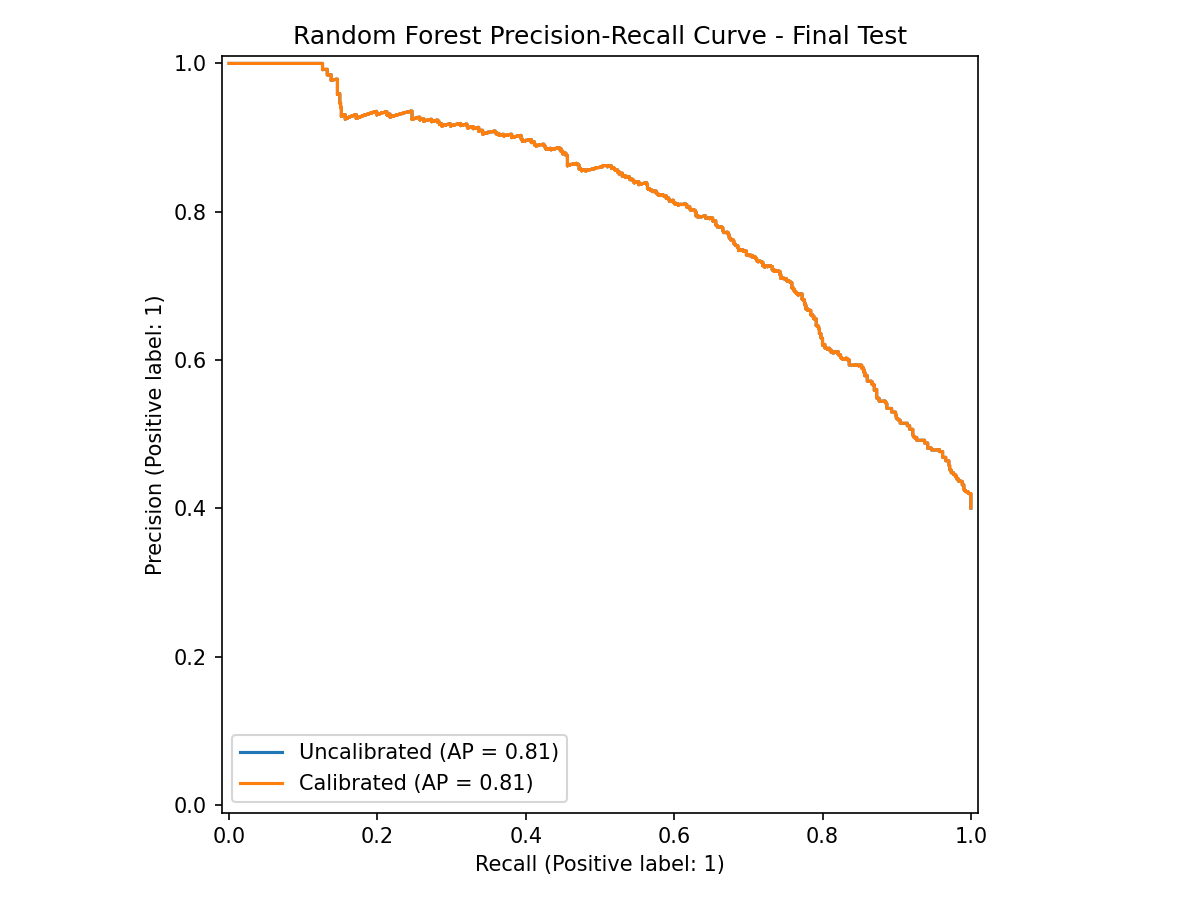

In [9]:
display(Image(filename=str(REPORT_DIR / "final_test_roc_curve.png")))
display(Image(filename=str(REPORT_DIR / "final_test_precision_recall_curve.png")))


## 10. Anonymous example predictions

These are example records from the historical final test set. Identifiers and customer details are not displayed.


In [10]:
examples = pd.read_csv(
    REPORT_DIR / "anonymous_example_predictions.csv"
)
display(examples.head(25))


,test_record_number,actual_late_payment,predicted_late_probability_percent,late_payment_alert
0,1,0,17.69,No alert
1,2,0,17.39,No alert
2,3,0,17.94,No alert
3,4,0,61.67,Alert
4,5,1,69.56,Alert
5,6,0,6.08,No alert
6,7,0,47.50,Alert
7,8,0,59.07,Alert
8,9,0,16.76,No alert
9,10,0,51.45,Alert


## 11. Predict late-payment risk for open invoices

The saved sigmoid-calibrated Random Forest is applied to the open invoice feature set.

These invoices have no known outcome labels. The resulting probabilities are predictions, not verified outcomes.

The alert threshold below is the calibrated equivalent of the previous raw Random Forest threshold of 0.40. It is provisional, not an independently optimized business threshold.


In [11]:
open_path = DATA_DIR / "invoices_features_open.parquet"
model_path = MODEL_DIR / "random_forest_calibrated.joblib"

open_df = pd.read_parquet(open_path)

missing_open_features = [
    col for col in features if col not in open_df.columns
]
assert not missing_open_features, missing_open_features

calibrated_model = joblib.load(model_path)

X_open = open_df[features]
open_probabilities = calibrated_model.predict_proba(X_open)[:, 1]

CALIBRATED_THRESHOLD = 0.3491532574508104

open_predictions = pd.DataFrame({
    "prediction_record": np.arange(1, len(open_df) + 1),
    "predicted_late_probability_percent": np.round(
        open_probabilities * 100, 2
    ),
    "late_payment_alert": np.where(
        open_probabilities >= CALIBRATED_THRESHOLD,
        "Alert",
        "No alert"
    )
})

output_path = REPORT_DIR / "open_invoice_risk_predictions.csv"
open_predictions.to_csv(output_path, index=False)

print("Open invoices scored:", len(open_predictions))
print("Prediction file:", output_path)
print("Mean predicted late probability:",
      round(open_probabilities.mean() * 100, 2), "%")
print("\nAlert counts:")
display(open_predictions["late_payment_alert"].value_counts().to_frame("invoices"))
display(open_predictions.head(20))


Open invoices scored: 9681
Prediction file: C:\invioce_data\reports\week4_modeling\open_invoice_risk_predictions.csv
Mean predicted late probability: 40.22 %

Alert counts:


,invoices
late_payment_alert,
No alert,5549
Alert,4132


,prediction_record,predicted_late_probability_percent,late_payment_alert
0,1,93.32,Alert
1,2,53.30,Alert
2,3,29.45,No alert
3,4,67.92,Alert
4,5,13.22,No alert
5,6,80.93,Alert
6,7,94.62,Alert
7,8,16.95,No alert
8,9,18.61,No alert
9,10,18.55,No alert


## 12. Limitations and conclusions

- Evaluation metrics are based on historical settled invoices. Open invoices do not have known labels, so performance on them cannot currently be verified.
- The historical data covers a limited time period. Performance may change as payment behaviour changes.
- The business definition of `total_open_amount` remains unconfirmed; this field was excluded.
- The alert threshold is provisional because the business costs of false positives and false negatives have not been quantified.
- Model comparisons used different imbalance treatments, which limits strict comparability.
- The five-fold time-aware cross-validation provides a more robust chronological comparison than a single random split.
- Random Forest was selected based on its mean F1 and recall across the five folds. XGBoost had stronger mean ROC-AUC and PR-AUC.

**Current candidate:** Sigmoid-calibrated Random Forest.

**Final historical test:** 2,359 invoices from February 1-27, 2020.

**Classification threshold:** 0.34915 on the calibrated probability scale, pending business validation.
